In [ ]:
%reset

In [2]:
%fdp_login

You already have a token for d3d valid for 19.7 hours.
  Logging in again would REPLACE it, and a new token lasts 24 hours.
  Run  %fdp_login d3d force  to replace it anyway.


## DIII-D shot 165340 — `\ipmhd` from `efit01`

The fetch returned a single clean record with no errors. The signal is the EFIT equilibrium reconstruction of plasma current, archived in **amperes** .

**Samples** : 311
**Time base** : 100.0 – 6360.0 ms, median interval 20.000 ms (50.00 Hz)
**Minimum** : 2.920250e+05 A (0.292 MA) at t = 6360.0 ms — the last sample, i.e. the end of the ramp-down
**Maximum** : 1.187812e+06 A (1.188 MA) at t = 3060.0 ms

The trace rises from 4.67e+05 A at the first sample (100 ms) to the 1.188 MA peak at 3060 ms, holds a plateau for most of the discharge — 228 of the 311 samples sit within 2% of the peak, spanning 920–5500 ms — then ramps down to 0.292 MA by 6360 ms. The mean over the whole trace is 1.077e+06 A and the median 1.180e+06 A; the median sitting near the peak rather than midway between min and max is the signature of a long flat-top with short ramps at each end. A linear fit over the rising edge (100–3060 ms) gives a ramp-up rate of 0.159 MA/s.


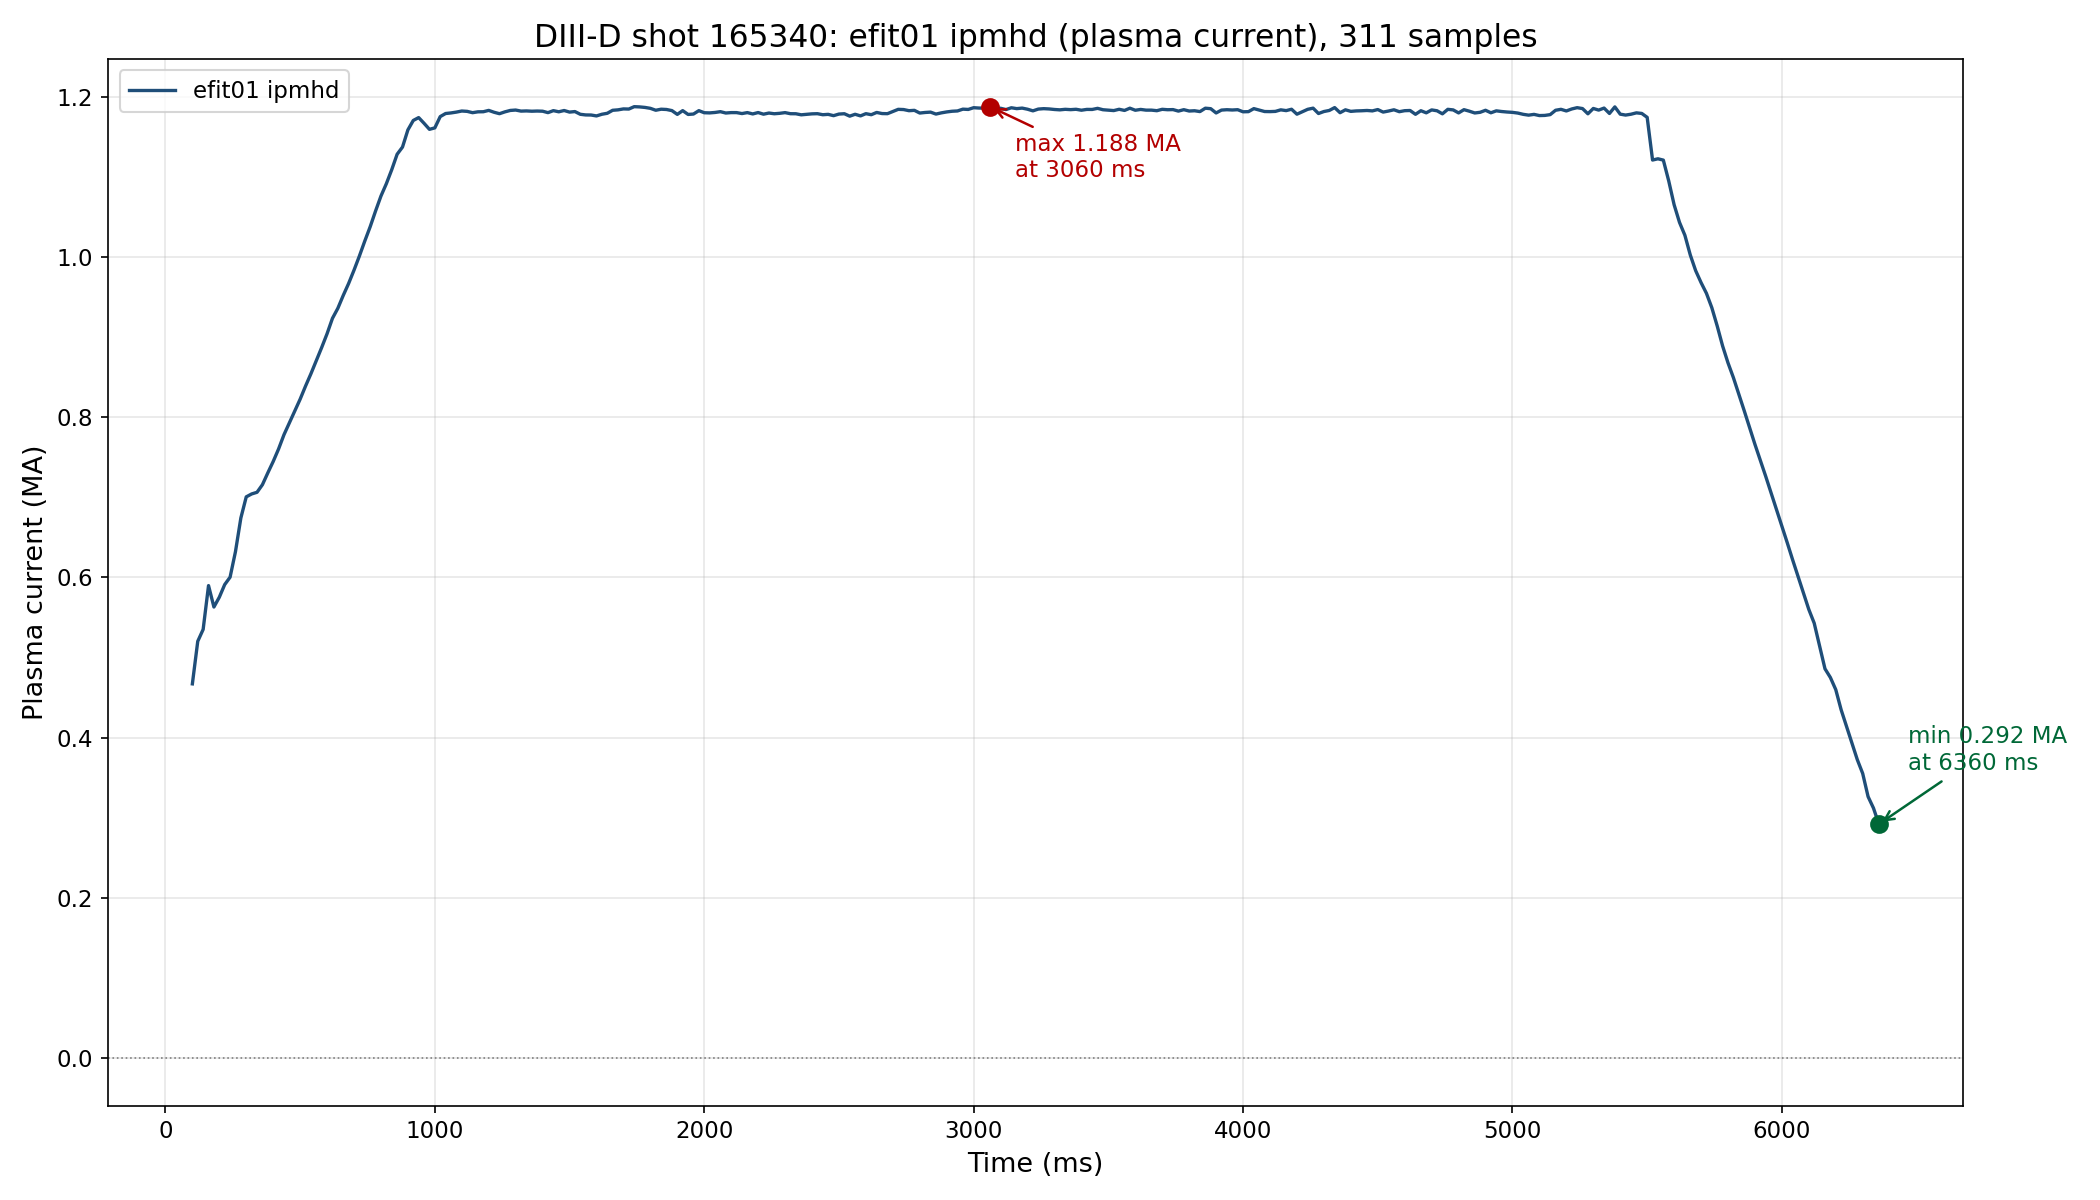

One note on the units: the record's own unit string is `A`, and the values are consistent with that — a ~1.2e6 reading is 1.2 MA, the expected plasma current for this machine. The chart plots the same data divided by 1e6 and is labelled in MA accordingly.

### Data files

- `ipmhd_165340.csv` — the full trace, 311 rows of `time_ms,ipmhd_A`, the source for every number above.
- `ipmhd_165340_stats.json` — sample count, time span, cadence, min/max with their times, mean and median, in both A and MA.
- `ipmhd_165340.png` — the chart shown above.
- `fetch_ipmhd_165340.py` — the fetch-and-plot script (run via `fdp run python`).
- `verify_ipmhd_165340.py` — the independent re-check that recomputed the statistics from the saved CSV.

In [3]:
%%ask
Fetch \ipmhd from efit01 for shot 165340 and plot it versus time, and
report the number of samples and the min/max with units.

**Short answer** : There are **9 tungsten samples** , and they are the entire sample inventory — every one of the 9 rows in `materials.samples` carries material `W`, so tungsten is not a subset here but the whole delivery. They come from a single delivery, `2026-09-04_amy`, received 2026-09-04.

The material field is `W`, which the FEDER ontology maps to **tungsten** as an `exact` match (`https://w3id.org/feder/ontology/v4/common-materials#Tungsten`), so the label and the count refer to the same thing.

### The nine samples

| Sample | Exposure history | Exposure records |
|---|---|---|
| W-pristine | Pristine (no exposure) | — |
| W-He800 | PISCES-A only | Exposure 1, PISCES, id 17 |
| W-He600 | PISCES-A only | Exposure 1, PISCES, id 18 |
| W-DH | DIII-D only | Exposure 2, DIII-D, id 19 |
| W-DL | DIII-D only | Exposure 2, DIII-D, id 20 |
| W-He800-DH | PISCES-A then DIII-D | Exposure 1 (id 17); Exposure 2 (id 19) |
| W-He600-DH | PISCES-A then DIII-D | Exposure 1 (id 18); Exposure 2 (id 19) |
| W-He800-DL | PISCES-A then DIII-D | Exposure 1 (id 17); Exposure 2 (id 20) |
| W-He600-DL | PISCES-A then DIII-D | Exposure 1 (id 18); Exposure 2 (id 20) |

**By exposure history** : 1 pristine, 2 PISCES-A only, 2 DIII-D only, 4 through both campaigns.


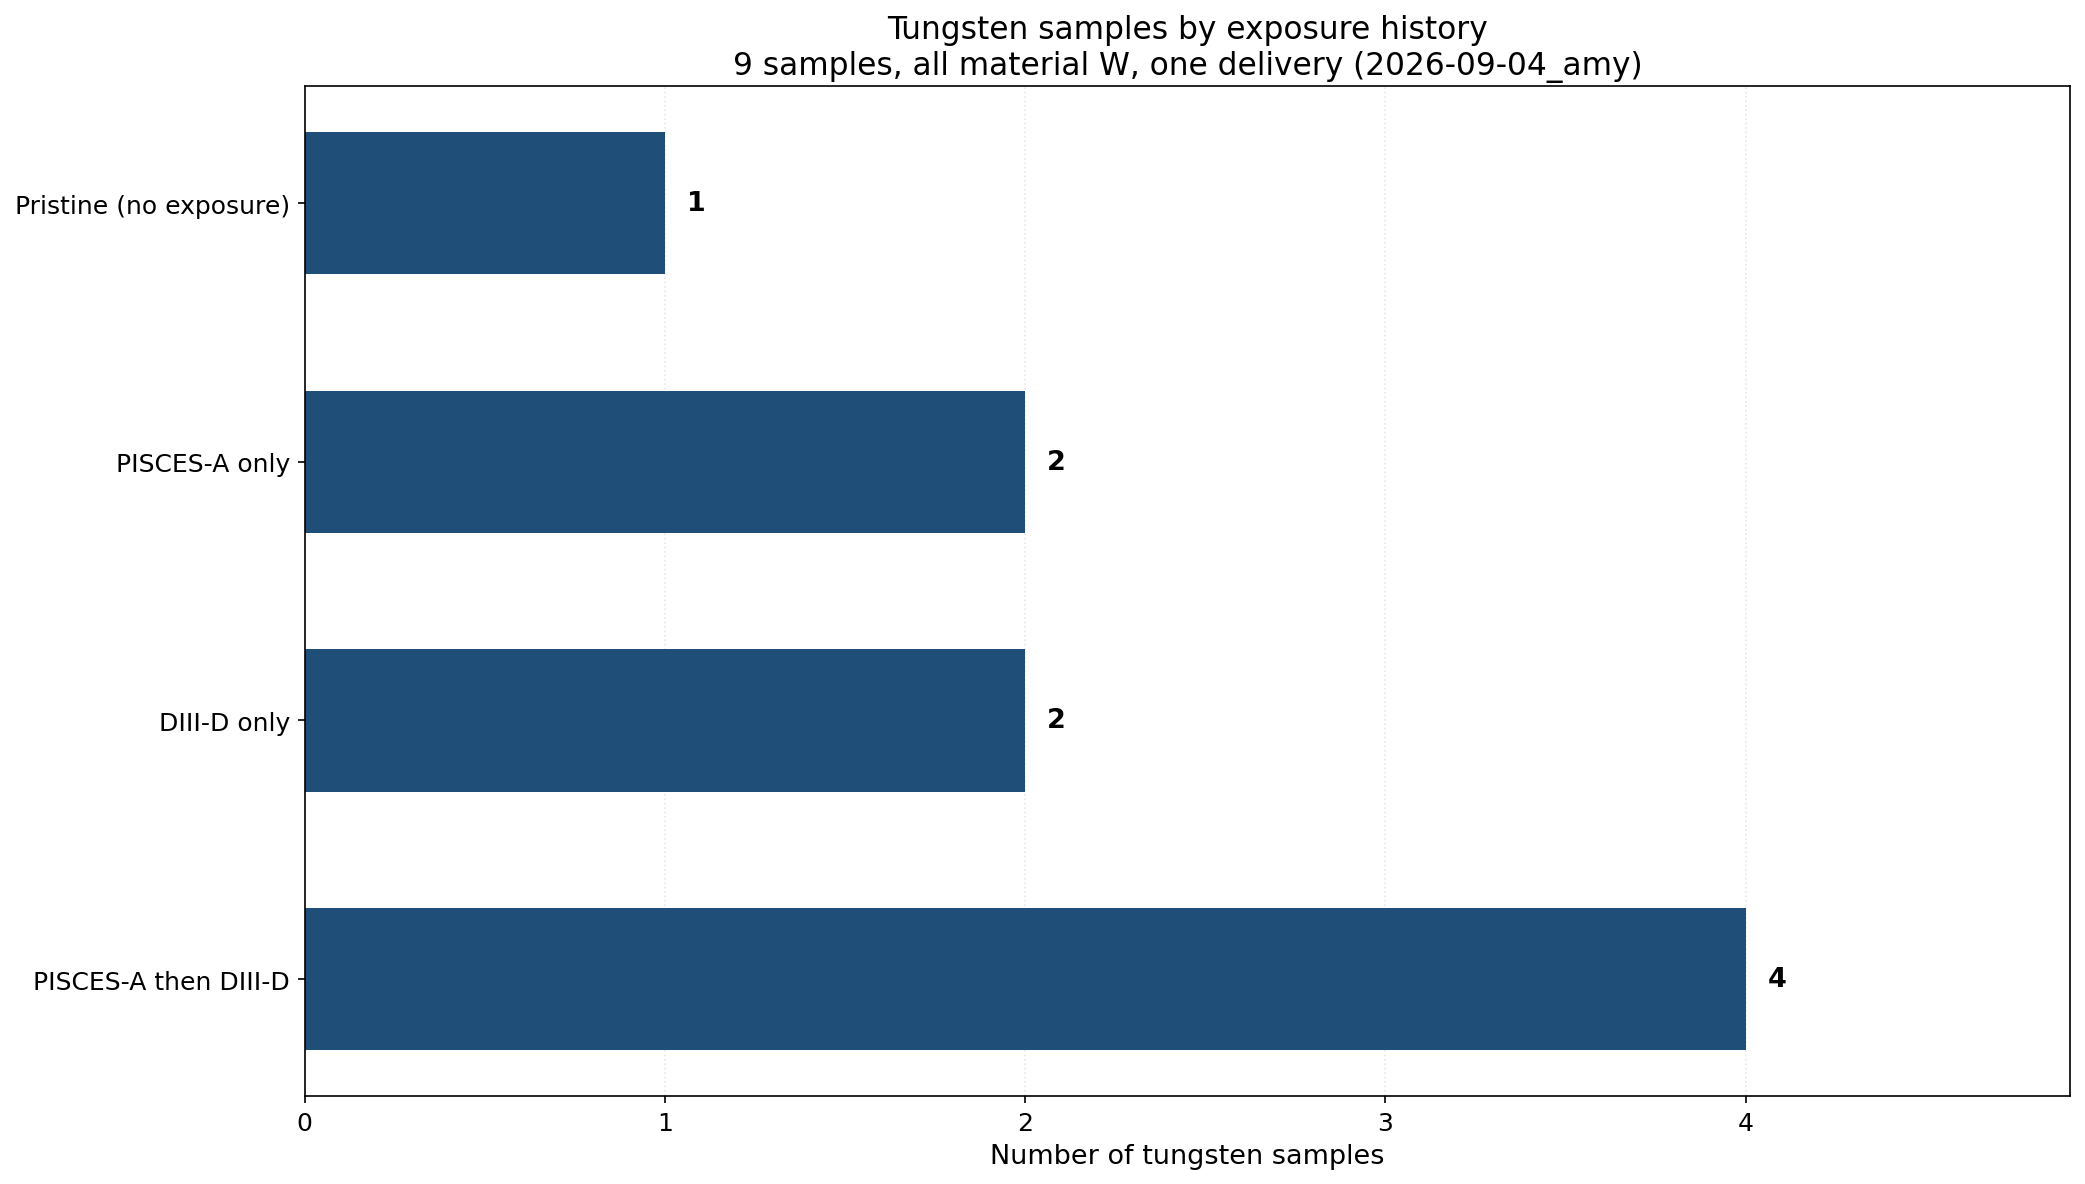

### What the count rests on

The number comes from a `GROUP BY material` over `materials.samples`, which returned one group — `W`, n = 9 — and from `mat.samples()`, which lists the same 9 names. Both agree, and the exposure breakdown sums back to 9.

Two things worth flagging about the structure, since they bear on what the 9 can support:

- **The design is fully crossed but unreplicated.** `mat.design()` returns 9 cells of exactly 1 sample each. The 4 samples that went through both campaigns are the 2×2 of He pre-exposure temperature (600 K, 800 K) against DIII-D mode (H-mode, L-mode), plus the single pristine control. With one coupon per cell, a difference between any two cells cannot be separated from coupon-to-coupon variation.
- **"Exposure 1" is two distinct exposures, not one.** The two PISCES-A records (ids 17 and 18) share the slot label but are separate campaigns — 800 K and 600 K respectively — so the He temperature is a treatment level carried by `exposure_id`, not by the slot name.

The delivery's provider notes record that `SiN` appears in the delivered workbook but is a calibration standard used by the measuring laboratory, not one of the experiment's samples; it is correctly absent from the 9. The notes also state that sample temperature during the DIII-D exposure was not measured, bulk or surface.

I searched the four papers attached to this delivery (Wagner 2007; Ziegler 2010; Guillemaut 2015; Baldwin & Doerner 2017) for anything bearing on the sample inventory. The hits were general tungsten plasma-facing-material background from other experiments — Baldwin & Doerner's Plansee W targets in PISCES-A, for instance — and none of them describes this delivery's coupons or their count, so no paper is cited for the number above.

### Data files

- `tungsten_samples.csv` — all 9 samples with material, exposure history, exposure records, description, investigator and delivery id.
- `tungsten_sample_count.json` — the counts, the exposure-history breakdown, the material list, and the ontology term with its IRI.
- `tungsten_samples_by_history.png` — the chart above.
- `tungsten_inventory.py` — the script that queried the lakehouse and wrote the three files.
- `verify_tungsten.py` — the independent re-read of the CSV and JSON confirming 9 rows, all `W`, and a breakdown summing to 9.

In [4]:
%%ask
How many tungsten samples do you have?